# 新闻标题能预测道琼斯指数涨跌吗？

**问题**：每天的世界新闻标题，真的能帮助预测道指（DJIA）第二天/当天的涨跌吗？如果有作用，它在统计上和经济上是真实的吗？

**用户**：一个刷到"AI 读新闻预测股市"广告的普通散户。

This project is a prototype and is not financial advice.

## 阶段 1：环境、数据清理、检查、切分、基准

### 1.0 导入与随机种子
为什么固定随机种子 42：之后的模型、bootstrap 都有随机性，固定种子才能让别人重跑得到一样的数字。

In [1]:
import random
import sys
from pathlib import Path

import numpy as np
import pandas as pd

# 让 notebook 能 import 项目根目录下的 src/
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src import data_utils as du
from src.evaluation import evaluate, confusion_table

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA = ROOT / "data"
pd.set_option("display.max_colwidth", 120)

### 1.1 读取并清理新闻数据
- 原始标题很多长这样：`b'Georgia downs two Russian warplanes...'`，这是 Python 字节串被直接写进了 CSV，`b'` 和结尾的 `'` 不是标题内容，要去掉。
- 有少数格子是空的（NaN），换成空字符串，免得后面打情绪分时报错。
- `Date` 转成日期类型并排序，因为之后所有切分都按时间来。

In [2]:
news_raw = pd.read_csv(DATA / "Combined_News_DJIA.csv")
news = du.load_news(DATA / "Combined_News_DJIA.csv")

print("行数、列数:", news.shape)
print("日期范围:", news["Date"].min().date(), "到", news["Date"].max().date())
print("每列标题的空值数（清理前，只显示非零的）:")
na = news_raw[du.HEADLINE_COLS].isna().sum()
print(na[na > 0])

has_prefix = news_raw[du.HEADLINE_COLS].apply(lambda s: s.astype(str).str.match(r'^b[\'"]')).sum().sum()
left = news[du.HEADLINE_COLS].apply(lambda s: s.str.match(r'^b[\'"]')).sum().sum()
print(f"清理前带 b'' 前缀的标题: {has_prefix}，清理后仍带前缀: {left}")

行数、列数: (1989, 27)
日期范围: 2008-08-08 到 2016-07-01
每列标题的空值数（清理前，只显示非零的）:
Top23    1
Top24    3
Top25    3
dtype: int64
清理前带 b'' 前缀的标题: 11920，清理后仍带前缀: 0


In [3]:
# 清理前后对比，看看效果
print("清理前:", news_raw.loc[0, "Top1"])
print("清理后:", news.loc[0, "Top1"])

清理前: b"Georgia 'downs two Russian warplanes' as countries move to brink of war"
清理后: Georgia 'downs two Russian warplanes' as countries move to brink of war


### 1.2 读取道指价格并检查 Label
数据集作者说 Label = 1 表示道指"上涨或持平"。我们用价格自己算一遍，看看和 Label 是否一致。
同时检查两种可能的定义：**收盘价对前一天收盘价**、**收盘价对当天开盘价**。哪种一致率接近 100%，就说明 Label 实际是按哪种定义做的。

In [4]:
# Kaggle 下载下来的文件名是 upload_DJIA_table.csv，两种名字都接受
djia_path = next(p for p in [DATA / "DJIA_table.csv", DATA / "upload_DJIA_table.csv"] if p.exists())
print("价格文件:", djia_path.name)
djia = du.load_djia(djia_path)
print("道指表:", djia.shape, djia["Date"].min().date(), "到", djia["Date"].max().date())

# 两张表的日期是否一一对应
only_news = set(news["Date"]) - set(djia["Date"])
only_djia = set(djia["Date"]) - set(news["Date"])
print("只在新闻表里的日期数:", len(only_news), "| 只在道指表里的日期数:", len(only_djia))

merged, rates = du.check_labels(news, djia)
pd.DataFrame(rates).T

价格文件: upload_DJIA_table.csv
道指表: (1989, 7) 2008-08-08 到 2016-07-01
只在新闻表里的日期数: 0 | 只在道指表里的日期数: 0


,compared_days,agreement
up_adjclose,1988.0,0.998994
up_close,1988.0,0.998994
up_open_close,1989.0,0.983409


In [5]:
# 把不一致的日子列出来看看（用收盘对前一天收盘的定义）
mismatch = merged[merged["up_adjclose"].notna() & (merged["up_adjclose"] != merged["Label"])]
print("不一致的天数:", len(mismatch))
mismatch[["Date", "Label", "Open", "Close", "Adj Close", "up_adjclose", "up_open_close"]].head(15)

不一致的天数: 2


,Date,Label,Open,Close,Adj Close,up_adjclose,up_open_close
1436,2014-04-24,0,16503.390625,16501.650391,16501.650391,1.0,0.0
1839,2015-11-27,0,17806.039062,17813.390625,17813.390625,1.0,1.0


**看不一致那两天的前后几行**：如果收盘价和前一天一模一样，按"涨或持平 = 1"的规则应该是 1，但 Label 是 0。

In [6]:
for d in mismatch["Date"]:
    i = djia.index[djia["Date"] == d][0]
    print(djia.loc[i - 1:i, ["Date", "Open", "Close", "Volume"]].merge(news[["Date", "Label"]], on="Date"), "\n")

        Date          Open         Close    Volume  Label
0 2014-04-23  16513.730469  16501.650391  76830000      0
1 2014-04-24  16503.390625  16501.650391  80340000      0 

        Date          Open         Close    Volume  Label
0 2015-11-25  17820.810547  17813.390625  82540000      1
1 2015-11-27  17806.039062  17813.390625  82540000      0 



**结论**：Label 是按"今天收盘价 ≥ 前一天收盘价"定义的（一致率 99.9%）；"收盘 ≥ 开盘"只有 98.3%，不是它的定义。
（道指是指数，没有分红调整，所以 Close 和 Adj Close 完全一样，两行结果相同。）

仅有的 2 个不一致日（2014-04-24、2015-11-27），价格表里的收盘价和前一天**一模一样**，2015-11-27 连成交量都和前一天相同——很像价格表把前一天的数据复制了一行，是价格表的数据质量问题，而 Label 可能来自另一份价格。
处理方式：**预测目标仍然用原始 Label**（它是题目定义的目标，而且只差 2 天）。但要记住：2015-11-27 在测试集里，阶段 6 用价格算收益时，这一天的收益会被算成 0。

### 1.3 按日期切分
- 训练集：2008-08-08 到 2014-12-31
- 测试集：2015-01-02 到 2016-07-01

为什么按日期而不是随机打乱：现实中我们只能用过去预测未来。如果随机打乱，模型会"偷看"到未来的日子，结果会虚高。

In [7]:
train, test = du.split_by_date(news)
assert train["Date"].max() < test["Date"].min()  # 确认训练集完全在测试集之前
assert len(train) + len(test) == len(news)        # 确认没有日子被漏掉

split_summary = pd.DataFrame({
    "起始": [train["Date"].min().date(), test["Date"].min().date()],
    "结束": [train["Date"].max().date(), test["Date"].max().date()],
    "天数": [len(train), len(test)],
    "涨的比例": [train["Label"].mean(), test["Label"].mean()],
}, index=["训练集", "测试集"])
split_summary

,起始,结束,天数,涨的比例
训练集,2008-08-08,2014-12-31,1611,0.541899
测试集,2015-01-02,2016-07-01,378,0.507937


### 1.4 两个基准（只在测试集上算）
任何 AI 模型都必须先打败这两个"笨办法"，否则就没有价值：
1. **永远预测涨**：股市长期大多数日子在涨，所以这个准确率不会太低。
2. **跟前一天同方向**：检验"动量"——昨天涨今天也涨。测试集第一天用训练集最后一天的 Label。

指标：准确率为主；再看混淆矩阵和"跌"的召回率（真实下跌的日子里，猜中了几成）。永远预测涨的"跌"召回率必然是 0，这说明光看准确率会被骗。

In [8]:
y_test = test["Label"].to_numpy()
preds = {
    "永远预测涨": du.baseline_always_up(test),
    "跟前一天同方向": du.baseline_previous_day(train, test),
}

results = pd.DataFrame([evaluate(y_test, p, name) for name, p in preds.items()]).set_index("model")
results

,accuracy,down_recall
model,,
永远预测涨,0.507937,0.000000
跟前一天同方向,0.457672,0.451613


In [9]:
for name, p in preds.items():
    print(f"\n=== {name} ===")
    print(confusion_table(y_test, p))


=== 永远预测涨 ===
         预测 跌(0)  预测 涨(1)
真实 跌(0)        0      186
真实 涨(1)        0      192

=== 跟前一天同方向 ===
         预测 跌(0)  预测 涨(1)
真实 跌(0)       84      102
真实 涨(1)      103       89


### Stage 1 summary
- **Data**: 1,989 trading days with 25 headlines each. 11,920 headlines had a stray `b''` wrapper (Python byte strings written straight into the CSV); all were removed. Only 7 headlines are missing (Top23–Top25) and were replaced with empty strings. The dates in the news table and the price table match one to one.
- **Split**: training set 1,611 days (54.2% up days), test set 378 days (50.8% up days). The test period is "harder": up days are about 3.4 percentage points rarer, so the lesson "the market usually goes up" that a model learns in training pays off less in testing.
- **Baselines (test set)**:
  - Always predict "up": accuracy **50.8%**, but down-day recall is **0%**. It never catches a single down day.
  - Same direction as the previous day: accuracy **45.8%**, worse than a coin flip; down-day recall 45.2%. In 2015–2016 daily Dow moves showed **no momentum**. Being below 50% may look like a "reversal" pattern, but a 4-point gap over 378 days can easily be chance, so I do not treat it as a rule.
- **What this means**: a news model has to beat **50.8%** consistently before it can claim to be useful. With only 378 test days, a gap of a few points may be pure luck — Stage 5 tests exactly this.

## 阶段 2：VADER 情绪特征 + 逻辑回归

### 2.0 思路
"AI 读新闻"最简单的版本：先判断每条标题是正面还是负面，再看"今天新闻整体偏负面"能不能预测道指下跌。

**VADER** 是一个专为短文本（推文、标题）设计的情绪词典 + 规则模型：它给每个词一个情绪分，再按规则处理否定（"not good"）、程度词（"very"）、感叹号等，最后输出 compound 分，范围 -1（极负面）到 +1（极正面）。
优点：快、透明、不需要训练。缺点：它是为社交媒体通用情绪设计的，不懂金融语境（比如 "rates cut" 对股市是好事，VADER 可能看成负面）——阶段 3 的 FinBERT 就是为了解决这个问题。

注意：这一阶段和原始数据一样，用的是**当天**的标题预测**当天**的涨跌。这可能有"偷看"问题，阶段 4 专门检验。

### 2.1 给每条标题打分
打分是对每条标题独立进行的，不从数据里"学"任何东西，所以对全部日期一起打分不会造成训练/测试之间的泄露。

In [10]:
from src.sentiment import vader_scores, daily_features

vader = vader_scores(news)
print("打分表形状:", vader.shape, "| 空标题(NaN)数:", int(vader.isna().sum().sum()))

# 看几个例子：最负面、最正面、中性
flat = pd.DataFrame({"headline": news[du.HEADLINE_COLS].to_numpy().ravel(),
                     "compound": vader.to_numpy().ravel()}).dropna()
pd.concat([flat.nsmallest(3, "compound"), flat.nlargest(3, "compound"),
           flat[flat["compound"] == 0].head(3)])

打分表形状: (1989, 25) | 空标题(NaN)数: 7


,headline,compound
17551,"The war on drugs in Mexico, decreed by Caldern, part-funded by millions of dollars in U.S. govt aids, has not only f...",-0.9898
47737,"China strongly rejected U.S.-led criticism of its human rights record at the U.N. Human Rights Council, saying the U...",-0.9854
10136,"Everyone knows Japan fought against the ban that would have helped save the bluefin tuna from imminent collapse, but...",-0.9846
32026,"Snowden Nominated for Freedom of Thought Prize ""Members of the European Parliament are officially nominating fugitiv...",0.9623
14510,"""If the eurozone falls apart, it will be because Germany did not do enough to save it. If the eurozone is saved, it ...",0.9618
8270,It is a great honor for me to stand here tonight as the first Somali journalist to win this award. By recognizing me...,0.9608
1,BREAKING: Musharraf to be impeached.,0.0000
5,150 Russian tanks have entered South Ossetia whilst Georgia shoots down two Russian jets.,0.0000
13,China tells Bush to stay out of other countries' affairs,0.0000


In [11]:
# 所有标题的情绪分布：世界新闻整体偏负面
print(f"负面(<=-0.05): {(flat.compound <= -0.05).mean():.1%}  "
      f"中性: {flat.compound.between(-0.05, 0.05, inclusive='neither').mean():.1%}  "
      f"正面(>=0.05): {(flat.compound >= 0.05).mean():.1%}")

负面(<=-0.05): 54.5%  中性: 25.1%  正面(>=0.05): 20.4%


### 2.2 每天汇总成特征
一天 25 条标题 → 7 个数字：平均分、最低分、最高分、标准差、负面占比、正面占比、Top1 的分数。
下面**只在训练集里**看看：涨的日子和跌的日子，这些特征平均有没有区别。如果连训练集里都看不出差别，模型也很难学到东西。

In [12]:
vader_feat = daily_features(vader, "vader")
feat_cols = list(vader_feat.columns)
data2 = pd.concat([news[["Date", "Label"]], vader_feat], axis=1)
train2, test2 = du.split_by_date(data2)

X_train, y_train = train2[feat_cols].to_numpy(), train2["Label"].to_numpy()
X_test, y_test = test2[feat_cols].to_numpy(), test2["Label"].to_numpy()

train2.groupby("Label")[feat_cols].mean().T.rename(columns={0: "跌的日子", 1: "涨的日子"})

Label,跌的日子,涨的日子
vader_mean,-0.225751,-0.212552
vader_min,-0.886882,-0.887947
vader_max,0.646831,0.660955
vader_std,0.430366,0.434254
vader_neg_share,0.559783,0.543382
vader_pos_share,0.197236,0.205762
vader_top1,-0.197408,-0.175671


In [13]:
# 每个特征和 Label 的相关系数（仅训练集）。|r| 接近 0 = 几乎没有线性关系
train2[feat_cols].corrwith(train2["Label"]).round(3).to_frame("与 Label 的相关系数")

,与 Label 的相关系数
vader_mean,0.071
vader_min,-0.008
vader_max,0.042
vader_std,0.036
vader_neg_share,-0.077
vader_pos_share,0.052
vader_top1,0.024


### 2.3 在训练集内部调参（TimeSeriesSplit，5 折）
- 模型：标准化 + 逻辑回归。逻辑回归简单、可解释，每个特征一个系数，能看出"负面新闻多 → 更可能跌"是否成立。
- 调的参数：正则化强度 C，以及是否给"跌"类加权（class_weight）。
- 选参数只看训练集内部的交叉验证分数，**测试集完全不碰**。
- 同时算"永远预测涨"在同样 5 个验证折上的准确率，作为训练集内部的对照。

In [14]:
from src.modeling import make_logreg, tune, cv_table, always_up_cv_accuracy, LOGREG_GRID, CV

for i, (tr, va) in enumerate(CV.split(X_train)):
    print(f"折 {i+1}: 训练 {train2.Date[tr[0]].date()}~{train2.Date[tr[-1]].date()} ({len(tr)}天) | "
          f"验证 {train2.Date[va[0]].date()}~{train2.Date[va[-1]].date()} ({len(va)}天)")

search_vader = tune(make_logreg(), LOGREG_GRID, X_train, y_train)
cv_table(search_vader).head(6)

折 1: 训练 2008-08-08~2009-09-03 (271天) | 验证 2009-09-04~2010-09-28 (268天)
折 2: 训练 2008-08-08~2010-09-28 (539天) | 验证 2010-09-29~2011-10-19 (268天)
折 3: 训练 2008-08-08~2011-10-19 (807天) | 验证 2011-10-20~2012-11-13 (268天)
折 4: 训练 2008-08-08~2012-11-13 (1075天) | 验证 2012-11-14~2013-12-06 (268天)
折 5: 训练 2008-08-08~2013-12-06 (1343天) | 验证 2013-12-09~2014-12-31 (268天)


,param_logisticregression__C,param_logisticregression__class_weight,mean_test_score,std_test_score
0,0.001,NaN,0.553731,0.027277
1,0.01,NaN,0.548507,0.032271
2,0.1,NaN,0.531343,0.036908
3,1.0,NaN,0.528358,0.039531
4,0.01,balanced,0.526119,0.026279
5,0.001,balanced,0.524627,0.030824


In [15]:
best = search_vader.best_index_
fold_scores = pd.DataFrame({
    "VADER 逻辑回归(最佳参数)": [search_vader.cv_results_[f"split{i}_test_score"][best] for i in range(5)],
    "永远预测涨": always_up_cv_accuracy(y_train),
}, index=[f"折{i+1}" for i in range(5)])
fold_scores.loc["平均"] = fold_scores.mean()
print("最佳参数:", search_vader.best_params_)
fold_scores.round(3)

最佳参数: {'logisticregression__C': 0.001, 'logisticregression__class_weight': None}


,VADER 逻辑回归(最佳参数),永远预测涨
折1,0.582,0.575
折2,0.563,0.556
折3,0.504,0.500
折4,0.549,0.563
折5,0.571,0.560
平均,0.554,0.551


### 2.4 最终评估：测试集（参数已在上一步固定，此处只用一次）

In [16]:
vader_model = search_vader.best_estimator_
preds["VADER 逻辑回归"] = vader_model.predict(X_test)

results = pd.DataFrame([evaluate(y_test, p, name) for name, p in preds.items()]).set_index("model")
results["预测为涨的比例"] = [p.mean() for p in preds.values()]
results.round(3)

,accuracy,down_recall,预测为涨的比例
model,,,
永远预测涨,0.508,0.000,1.000
跟前一天同方向,0.458,0.452,0.505
VADER 逻辑回归,0.505,0.011,0.987


In [17]:
print(confusion_table(y_test, preds["VADER 逻辑回归"]))

         预测 跌(0)  预测 涨(1)
真实 跌(0)        2      184
真实 涨(1)        3      189


### 2.5 模型学到了什么？
系数是在标准化后的特征上算的，所以可以直接比大小：正系数 = 这个特征越大，模型越倾向预测"涨"。

In [18]:
coef = pd.Series(vader_model[-1].coef_[0], index=feat_cols).sort_values()
coef.round(4).to_frame("系数")

,系数
vader_neg_share,-0.0338
vader_min,-0.0087
vader_top1,0.0090
vader_std,0.0120
vader_max,0.0147
vader_pos_share,0.0151
vader_mean,0.0272


### Stage 2 summary
- **The sentiment itself**: world news is mostly negative (54.5% of headlines negative, only 20.4% positive). In the training set, up days and down days have almost identical sentiment features: every feature's correlation with the label is below 0.08 in absolute value. The direction does match intuition (a higher share of negative headlines goes with more down days, r = −0.077), but it is very weak.
- **The tuning result tells the story**: cross-validation picked the strongest regularisation, C = 0.001 (the smallest value in the grid). In plain words: "better not trust these features much", so the model almost always predicts "up". Its 5-fold training-set average is 55.4% versus 55.1% for "always up" — only 0.3 points better, and it loses in fold 4.
- **Test set**: the VADER logistic regression scores **50.5%**, below "always up" (50.8%). It predicts "up" on 98.7% of days and catches only 2 of 186 down days (down recall 1.1%).
- **Coefficients**: the share of negative headlines has the most negative coefficient (−0.034) and the mean score the most positive (+0.027). The directions make sense, but strong regularisation pushed all of them close to 0.
- **Conclusion**: with general-purpose VADER sentiment, world-news headlines show **no usable predictive power**; the model collapses to "always up". Possible reasons: (1) VADER does not understand financial context; (2) top r/worldnews headlines are mostly politics and society, with little link to US stocks; (3) daily moves are close to random anyway. Stage 3 tests reason (1) with the finance-specific FinBERT.
- Note: after seeing the test results I only fixed two display issues (the parameter None shown as NaN, and a misaligned comparison column). **No model, feature or parameter was changed.**

## 阶段 3：FinBERT（金融专用情绪模型）

### 3.0 思路
阶段 2 的一个可能原因是 VADER 不懂金融语境。**FinBERT** 是在 BERT 语言模型基础上，用金融新闻句子（Financial PhraseBank）继续训练出来的情绪分类器，专门判断一句话对市场/公司是 positive、negative 还是 neutral。

- 每条标题得到三个概率（加起来 = 1），我们定义 **情绪分 = P(positive) − P(negative)**，范围 -1 到 +1，和 VADER 的 compound 可以直接对比。
- 这里只用现成模型做**推理**，不在我们的数据上训练，所以和阶段 2 一样不会造成训练/测试泄露。
- 约 5 万条标题在 CPU 上要算几十分钟，结果缓存到 `data/finbert_scores.csv`，之后直接读取。
- 每天的特征和阶段 2 完全一样（7 个），只是负面/正面占比改成按"概率最大的类别"来数。

In [19]:
from src.finbert import finbert_scores, to_wide

fb_long = finbert_scores(news, DATA / "finbert_scores.csv")
fb_long["score"] = fb_long["positive"] - fb_long["negative"]
fb_long["label"] = fb_long[["positive", "negative", "neutral"]].idxmax(axis=1)
print("打分的标题数:", len(fb_long))
fb_long["label"].value_counts(normalize=True).round(3).to_frame("FinBERT 标签占比")

从缓存读取: finbert_scores.csv


打分的标题数: 49718


,FinBERT 标签占比
label,
negative,0.506
neutral,0.436
positive,0.058


### 3.1 FinBERT 和 VADER 的看法一样吗？
如果两者几乎一样，换模型就没有意义；如果差别很大，就值得看看谁更"懂"金融。

In [20]:
# 把 FinBERT 结果和 VADER 结果按 (日期, 排名) 对齐
vader_long = vader.assign(Date=news["Date"]).melt(id_vars="Date", var_name="rank", value_name="vader")
vader_long["rank"] = vader_long["rank"].str.replace("Top", "").astype(int)
cmp = fb_long.merge(vader_long, on=["Date", "rank"])
cmp["vader_label"] = pd.cut(cmp["vader"], [-1.01, -0.05, 0.05 - 1e-9, 1.01],
                            labels=["negative", "neutral", "positive"])

print(f"单条标题情绪分的相关系数（FinBERT vs VADER）: {cmp['score'].corr(cmp['vader']):.3f}")
print(f"三分类标签一致的比例: {(cmp['label'] == cmp['vader_label'].astype(str)).mean():.1%}")
pd.crosstab(cmp["vader_label"], cmp["label"], normalize="index").round(3).rename_axis(index="VADER ↓ / FinBERT →")

单条标题情绪分的相关系数（FinBERT vs VADER）: 0.431
三分类标签一致的比例: 54.5%


label,negative,neutral,positive
VADER ↓ / FinBERT →,,,
negative,0.666,0.308,0.025
neutral,0.336,0.607,0.057
positive,0.289,0.566,0.146


In [21]:
# 分歧最大的例子：一个说很正面、另一个说很负面
flat_headlines = news.melt(id_vars="Date", value_vars=du.HEADLINE_COLS, var_name="rank", value_name="headline")
flat_headlines["rank"] = flat_headlines["rank"].str.replace("Top", "").astype(int)
cmp = cmp.merge(flat_headlines, on=["Date", "rank"])
cmp["gap"] = cmp["score"] - cmp["vader"]
show = ["headline", "vader", "score"]
pd.concat([cmp.nlargest(4, "gap")[show], cmp.nsmallest(4, "gap")[show]]).round(2).rename(columns={"score": "finbert"})

,headline,vader,finbert
19107,"Chile officially recognized 9,800 more Pinochet victims, increasing the total number of people killed, tortured or i...",-0.92,0.89
10228,"Ciudad Jurez is one of the fastest growing cities in the world, in spite of the fact that it is ""the most violent zo...",-0.90,0.90
46907,Violent crime rises by 27% after killings hit a five-year high in the UK,-0.92,0.84
11090,"Portugal unveils crisis tax to cut deficit - Jos Scrates, Portugals prime minister, on Thursday announced tough new ...",-0.95,0.78
7530,"For the past two years, Sudanese-born cellphone magnate Mo Ibrahim has given out $5 million prizes to outstanding Af...",0.94,-0.92
13674,Norway says China has canceled a ministerial meeting apparently in response to the award of the Nobel peace prize to...,0.88,-0.93
47927,Massive Bleaching Event Hits the Great Barrier Reef: Warm ocean temperatures have impacted large swaths of the Great...,0.84,-0.95
44074,Canadians pull the plug on renewable energy scheme - Canadian province of Nova Scotia cancels a successful project w...,0.85,-0.94


### 3.2 每天的 FinBERT 特征
和阶段 2 一样，先只在训练集里看涨的日子和跌的日子有没有区别。

In [22]:
fb_score_wide = to_wide(fb_long, "score")
fb_label_wide = to_wide(fb_long, "label")
assert len(fb_score_wide) == len(news)

fb_feat = daily_features(fb_score_wide, "finbert",
                         is_neg=fb_label_wide.eq("negative"), is_pos=fb_label_wide.eq("positive"))
fb_cols = list(fb_feat.columns)
data3 = pd.concat([news[["Date", "Label"]], vader_feat, fb_feat], axis=1)
train3, test3 = du.split_by_date(data3)

train3.groupby("Label")[fb_cols].mean().T.rename(columns={0: "跌的日子", 1: "涨的日子"}).round(4)

Label,跌的日子,涨的日子
finbert_mean,-0.3735,-0.3658
finbert_min,-0.9293,-0.9276
finbert_max,0.5880,0.5947
finbert_std,0.4453,0.4470
finbert_neg_share,0.5096,0.5012
finbert_pos_share,0.0498,0.0542
finbert_top1,-0.3368,-0.3421


In [23]:
train3[fb_cols].corrwith(train3["Label"]).round(3).to_frame("与 Label 的相关系数（训练集）")

,与 Label 的相关系数（训练集）
finbert_mean,0.039
finbert_min,0.032
finbert_max,0.012
finbert_std,0.014
finbert_neg_share,-0.039
finbert_pos_share,0.047
finbert_top1,-0.006


### 3.3 调参 + 测试
用和阶段 2 **完全相同**的流程（同样的网格、同样的 5 折时间序列交叉验证）训练两个模型：
1. 只用 FinBERT 的 7 个特征
2. VADER + FinBERT 一共 14 个特征（看两者合起来是否更好）

`run_experiment` 把"切分 → 训练集内调参 → 测试集评估一次"包成一个函数，保证做法一致。

In [24]:
from src.modeling import run_experiment

rows3 = {}
row, search_fb = run_experiment(data3, fb_cols, name="FinBERT 逻辑回归")
rows3["FinBERT"] = row
row, search_both = run_experiment(data3, feat_cols + fb_cols, name="VADER+FinBERT 逻辑回归")
rows3["VADER+FinBERT"] = row

best = search_fb.best_index_
fold_fb = pd.DataFrame({
    "FinBERT 逻辑回归(最佳参数)": [search_fb.cv_results_[f"split{i}_test_score"][best] for i in range(5)],
    "永远预测涨": always_up_cv_accuracy(train3["Label"].to_numpy()),
}, index=[f"折{i+1}" for i in range(5)])
fold_fb.loc["平均"] = fold_fb.mean()
print("FinBERT 最佳参数:", search_fb.best_params_)
print("VADER+FinBERT 最佳参数:", search_both.best_params_)
fold_fb.round(3)

FinBERT 最佳参数: {'logisticregression__C': 0.001, 'logisticregression__class_weight': None}
VADER+FinBERT 最佳参数: {'logisticregression__C': 0.001, 'logisticregression__class_weight': None}


,FinBERT 逻辑回归(最佳参数),永远预测涨
折1,0.549,0.575
折2,0.556,0.556
折3,0.500,0.500
折4,0.563,0.563
折5,0.560,0.560
平均,0.546,0.551


In [25]:
X_test3 = test3[fb_cols].to_numpy()
preds["FinBERT 逻辑回归"] = search_fb.best_estimator_.predict(X_test3)
preds["VADER+FinBERT 逻辑回归"] = search_both.best_estimator_.predict(test3[feat_cols + fb_cols].to_numpy())

results = pd.DataFrame([evaluate(y_test, p, name) for name, p in preds.items()]).set_index("model")
results["预测为涨的比例"] = [p.mean() for p in preds.values()]
results.round(3)

,accuracy,down_recall,预测为涨的比例
model,,,
永远预测涨,0.508,0.000,1.000
跟前一天同方向,0.458,0.452,0.505
VADER 逻辑回归,0.505,0.011,0.987
FinBERT 逻辑回归,0.508,0.000,1.000
VADER+FinBERT 逻辑回归,0.505,0.022,0.976


In [26]:
print(confusion_table(y_test, preds["FinBERT 逻辑回归"]))
pd.Series(search_fb.best_estimator_[-1].coef_[0], index=fb_cols).sort_values().round(4).to_frame("FinBERT 模型系数")

         预测 跌(0)  预测 涨(1)
真实 跌(0)        0      186
真实 涨(1)        0      192


,FinBERT 模型系数
finbert_neg_share,-0.0165
finbert_top1,-0.0061
finbert_max,-0.0005
finbert_std,0.0019
finbert_mean,0.0137
finbert_min,0.0155
finbert_pos_share,0.0240


### 3.4 FinBERT 可靠吗？
FinBERT 没有带来预测能力，可能是"模型坏了"，也可能是"模型没问题，只是不适合这些标题"。分三步检查：
1. 给几句意思很明确的句子打分，看模型本身是否正常（包括正负标签有没有弄反）
2. 在它的"本行"——报道股市行情的标题上，判断得准不准
3. 在世界新闻上，有没有系统性的错误

In [27]:
from src.finbert import score_texts

probe = [
    "Stocks plunge as recession fears grow",
    "Company profits beat expectations, shares soar",
    "Oil prices fall sharply, hurting energy firms",
    "The central bank left interest rates unchanged",
    "Fed cuts interest rates",
    "Unemployment rises to 10%",
    "Violent crime rises by 27%",
    "Death toll rises to 300 after earthquake",
]
probe_scores, _ = score_texts(probe)
probe_scores["情绪分"] = probe_scores["positive"] - probe_scores["negative"]
probe_scores.insert(0, "句子", probe)
probe_scores.round(2)

FinBERT 运行设备: cpu


  已打分 8/8


,句子,positive,negative,neutral,情绪分
0,Stocks plunge as recession fears grow,0.01,0.94,0.04,-0.93
1,"Company profits beat expectations, shares soar",0.92,0.03,0.05,0.89
2,"Oil prices fall sharply, hurting energy firms",0.01,0.97,0.02,-0.96
3,The central bank left interest rates unchanged,0.05,0.23,0.73,-0.18
4,Fed cuts interest rates,0.03,0.82,0.15,-0.79
5,Unemployment rises to 10%,0.72,0.25,0.03,0.47
6,Violent crime rises by 27%,0.72,0.22,0.06,0.50
7,Death toll rises to 300 after earthquake,0.08,0.72,0.19,-0.64


In [28]:
# 第 2 步：明确在说"股市跌了"的标题（和 4.1 节同一套关键词规则）
check = cmp.merge(news[["Date", "Label"]], on="Date")
is_market = check["headline"].str.contains(du.MARKET_WORDS, case=False)
says_down = (check["headline"].str.contains(du.DOWN_WORDS, case=False)
             & ~check["headline"].str.contains(du.UP_WORDS, case=False))
market_down = check[is_market & says_down]
market_all = check[is_market]

pd.DataFrame({
    "判为负面的比例（说股市跌的标题）": [(market_down["label"] == "negative").mean(),
                          (market_down["vader_label"] == "negative").mean()],
    "情绪分与当天 Label 的相关（所有提到股市的标题）": [market_all["score"].corr(market_all["Label"]),
                                 market_all["vader"].corr(market_all["Label"])],
}, index=["FinBERT", "VADER"]).round(3).assign(标题数=[len(market_down), len(market_down)])

,判为负面的比例（说股市跌的标题）,情绪分与当天 Label 的相关（所有提到股市的标题）,标题数
FinBERT,1.000,0.068,38
VADER,0.632,-0.005,38


In [29]:
# 第 3 步："坏事 + 上升"陷阱：死亡、犯罪、失业、病例……在"上升"
RISE = r"\b(?:rise[sn]?|rose|rising|increase[sd]?|increasing|grow(?:s|ing|n)?|soar(?:s|ed|ing)?|surge[sd]?|jump(?:s|ed)?)\b"
BAD = (r"\b(?:death|dead|deaths|killed|toll|crime|violence|unemployment|cases|casualties"
       r"|victims|suicides?|poverty|infections?)\b")
trap = check[check["headline"].str.contains(RISE, case=False) & check["headline"].str.contains(BAD, case=False)]

print(f"“坏事 + 上升”标题: {len(trap)} 条")
print(pd.DataFrame({
    "这类标题里判为正面": [(trap["label"] == "positive").mean(), (trap["vader_label"] == "positive").mean()],
    "全部标题里判为正面": [(check["label"] == "positive").mean(), (check["vader_label"] == "positive").mean()],
}, index=["FinBERT", "VADER"]).round(3))
trap[trap["label"] == "positive"].nlargest(5, "score")[["headline", "score", "vader"]].round(2).rename(columns={"score": "finbert"})

“坏事 + 上升”标题: 182 条
         这类标题里判为正面  全部标题里判为正面
FinBERT      0.170      0.058
VADER        0.077      0.204


,headline,finbert,vader
20885,BBC News - Eurozone unemployment rate rises to 10.3%. Youth unemployment in Spain rose to 48.9%.,0.91,-0.70
29887,Greek Youth Unemployment Rises Above 60 Percent,0.89,-0.44
19107,"Chile officially recognized 9,800 more Pinochet victims, increasing the total number of people killed, tortured or i...",0.89,-0.92
39202,"Ebola jumps to 13,703 cases. 30% increase in 4 days says WHO.",0.88,0.32
34174,"Spain Youth Unemployment Rises To Record 57.7%, Surpasses Greece",0.86,-0.44


In [30]:
# 模型对世界新闻有多"确定"？最大类别概率越接近 1 越确定
conf = fb_long[["positive", "negative", "neutral"]].max(axis=1)
print(f"最大类别概率的中位数: {conf.median():.2f}；低于 0.6（拿不准）的标题占 {(conf < 0.6).mean():.0%}")

最大类别概率的中位数: 0.81；低于 0.6（拿不准）的标题占 15%


**Section 3.4 conclusion: FinBERT works, but it answers a different question from ours.**
- The model itself is fine: it gets clear financial sentences right, and its positive/negative labels are not swapped.
- On its home ground it beats VADER: it labels every headline that says stocks fell as negative (VADER: about 63%).
- Outside finance it is systematically biased: it learned surface rules like "rise/increase = good, cut = bad" without checking *what* is rising — "Unemployment rises to 10%" and "Violent crime rises by 27%" come out positive, and "bad thing + rises" headlines are labelled positive far more often than headlines in general. It errs even inside finance: "Fed cuts interest rates" is usually good news for stocks, yet it is scored strongly negative.
- It also stays confident on this unfamiliar text (median top-class probability ≈ 0.8), so it never signals "I'm not sure".
- So FinBERT measures "does this sentence read like good financial news", not "is this world event good or bad for US stocks". Only 0.4% of r/worldnews headlines actually discuss markets, so its strength is almost never used.

### Stage 3 summary
- **FinBERT is gloomier than VADER**: it labels 50.6% of headlines negative, 43.6% neutral and only 5.8% positive (VADER: 20.4% positive).
- **The two models only partly agree**: the per-headline correlation of their scores is 0.43, and they give the same three-way label only 54.5% of the time. Of the headlines VADER calls positive, FinBERT agrees on just 14.6%.
- **The biggest disagreements reveal FinBERT's weakness**: it was trained on company and earnings news, so words like *rises*, *increasing* and *growing* push it towards "positive" — "Violent crime rises by 27%" scores +0.84 and "Chile officially recognized 9,800 more Pinochet victims, increasing the total…" scores +0.89. In the other direction, business-flavoured bad words such as "canceled", "pull the plug" and "impacted" are scored very negative. Calling "Portugal unveils crisis tax to cut deficit" positive is at least sound financial logic. **In short, FinBERT understands financial language but not world news** — switching models fixed one problem and introduced another.
- **The Section 3.4 checks**: the model itself works correctly and beats VADER on headlines that actually report stock moves, but it is systematically biased on world news ("unemployment rises" → positive, "Fed cuts interest rates" → negative) and stays confident even when it is wrong.
- **The features still do not separate up and down days**: in the training set, up days and down days look almost the same, and every feature's correlation with the label is at most 0.047 in absolute value — weaker than VADER.
- **Tuning**: both models again chose the strongest regularisation, C = 0.001. The FinBERT model averages 54.6% over the 5 training folds, **below** "always up" (55.1%).
- **Test set**: the FinBERT logistic regression predicts "up" on 100% of days, so it is identical to "always up" (50.8%). VADER + FinBERT together score 50.5% and catch only 4 of 186 down days.
- **Conclusion**: reason (1) from Stage 2, "VADER doesn't understand finance", is **not the main reason** — a finance-specific model finds no signal either. Reasons (2) (the headlines have little to do with US stocks) and (3) (daily moves are close to random) are more likely.
- Note: after seeing the test results, no model, parameter or feature was changed.

## 阶段 4：是不是在"偷看"？（同一天 vs 前一天的新闻）

### 4.0 问题在哪
原始数据用**当天**的标题预测**当天**的涨跌（收盘对前一天收盘）。可是：
- 这些标题是 r/worldnews 一整天的热门帖子，美股下午 4 点（美东）就收盘了，之后发的帖子**已经知道当天涨跌**。
- 有的标题本身就在报道市场（"Stocks plunge as …"），这等于把答案写进了题目。

真实的散户在开盘前只能看到**昨天**的新闻。所以要比较三种设定：

| 设定 | 特征 | 目标 | 能不能真的用来交易？ |
|---|---|---|---|
| A 同一天 | 第 t 天标题 | 第 t 天 收盘 ≥ 第 t−1 天收盘（原始 Label） | 不能，有"偷看"风险 |
| B 前一天 | 第 t−1 天标题 | 第 t 天 收盘 ≥ 第 t−1 天收盘 | 大部分可以，但第 t−1 天收盘后的新闻也算进了特征，而它影响的隔夜跳空也在目标里 |
| C 前一天 → 今天盘中 | 第 t−1 天标题 | 第 t 天 收盘 ≥ 第 t 天开盘 | **可以**：开盘时昨天的新闻全都已知，开盘买入、收盘卖出 |

如果 A 明显好于 B、C，说明 A 的"效果"来自偷看，不是预测。

### 4.1 直接找证据：标题里有没有在报道股市？

In [31]:
# 关键词规则在 src/data_utils.py 里（MARKET_WORDS / DOWN_WORDS / UP_WORDS），3.4 节也用同一套
hl = flat_headlines[flat_headlines["headline"] != ""].copy()
hl["market"] = hl["headline"].str.contains(du.MARKET_WORDS, case=False)
mk = hl[hl["market"]].copy()
mk["说跌"] = mk["headline"].str.contains(du.DOWN_WORDS, case=False)
mk["说涨"] = mk["headline"].str.contains(du.UP_WORDS, case=False)
mk = mk.merge(news[["Date", "Label"]], on="Date")
print(f"提到股市的标题: {len(mk)} 条（占全部 {len(mk) / len(hl):.1%}），分布在 {mk['Date'].nunique()} 天")

only_down = mk[mk["说跌"] & ~mk["说涨"]]
only_up = mk[mk["说涨"] & ~mk["说跌"]]
pd.DataFrame({
    "标题数": [len(only_down), len(only_up), len(mk), len(hl)],
    "当天真的涨的比例": [only_down["Label"].mean(), only_up["Label"].mean(), mk["Label"].mean(),
                    hl.merge(news[["Date", "Label"]], on="Date")["Label"].mean()],
}, index=["提到股市 + 只说跌", "提到股市 + 只说涨", "所有提到股市的", "全部标题（对照）"]).round(3)

提到股市的标题: 185 条（占全部 0.4%），分布在 162 天


,标题数,当天真的涨的比例
提到股市 + 只说跌,38,0.263
提到股市 + 只说涨,2,1.000
所有提到股市的,185,0.400
全部标题（对照）,49718,0.535


In [32]:
# 举几个例子：标题说股市跌，当天 Label 是多少？
only_down.sort_values("Date")[["Date", "headline", "Label"]].head(8)

,Date,headline,Label
15,2008-09-15,EU Stocks plunge!,0
123,2008-09-17,Russian stock market falls 17%,0
24,2008-09-17,"Russian stock exchanges halt trades, drop 60% since May",0
61,2008-10-06,Biggest ever fall in UK stocks,0
162,2008-10-13,Bank shares fall despite bail-out,1
168,2010-04-28,"Greece bans short-selling as panic spreads, Shares tumble across Britain, Europe and Asia after the cost of insuring...",1
99,2011-06-06,The Revolution Blows Up --- \nEgypts stock market is tanking and its rich are taking their money to Zurich. Will an ...,0
17,2011-07-13,Rupert Murdoch is bleeding cash trying to save plummeting News Corp: The growing phone hacking scandal has sent News...,1


### 4.2 三种设定 × 两种情绪特征
- B、C 的做法：把每天的特征**整体往后挪一天**（第 t 行放第 t−1 天的特征），第一天没有"前一天"，删掉。测试集第一天用的是训练集最后一天的新闻，那是过去的信息，没问题。
- C 的目标用道指价格算：当天收盘 ≥ 当天开盘 = 1。
- 每个组合都跑一遍 `run_experiment`（同样的调参、同样的切分），并且列出"永远预测涨"在同一目标上的准确率作对照——三种目标涨的比例不一样，**只能和同一目标的基准比**。

In [33]:
feature_sets = {"VADER": feat_cols, "FinBERT": fb_cols}

base = data3.merge(djia[["Date", "Open", "Close"]], on="Date")
base["up_intraday"] = (base["Close"] >= base["Open"]).astype(int)

prev = base.copy()
prev[feat_cols + fb_cols] = prev[feat_cols + fb_cols].shift(1)   # 第 t 行 ← 第 t-1 天的新闻特征
prev = prev.dropna(subset=feat_cols + fb_cols).reset_index(drop=True)

settings = {
    "A 同一天新闻 → 当天涨跌": (base, "Label"),
    "B 前一天新闻 → 当天涨跌": (prev, "Label"),
    "C 前一天新闻 → 当天盘中涨跌": (prev, "up_intraday"),
}

rows4 = []
tests4 = {}
searches4 = {}
for s_name, (df, target) in settings.items():
    for f_name, cols in feature_sets.items():
        row, search = run_experiment(df, cols, label_col=target, name=f_name)
        row["设定"] = s_name
        rows4.append(row)
        searches4[(s_name, f_name)] = search
        te = du.split_by_date(df)[1]   # 存下测试集的真实值和预测，阶段 5 做统计检验
        tests4[(s_name, f_name)] = (te[target].to_numpy(), search.best_estimator_.predict(te[cols].to_numpy()))

table4 = pd.DataFrame(rows4).set_index(["设定", "model"])
table4["测试集 比基准"] = table4["accuracy"] - table4["test_always_up"]
table4[["cv_accuracy", "cv_always_up", "accuracy", "test_always_up", "测试集 比基准",
        "down_recall", "pred_up_share", "best_C", "class_weight"]].round(3)

cv_accuracy  cv_always_up  accuracy  test_always_up  \
设定               model                                                          
A 同一天新闻 → 当天涨跌   VADER          0.554         0.551     0.505           0.508   
                 FinBERT        0.546         0.551     0.508           0.508   
B 前一天新闻 → 当天涨跌   VADER          0.544         0.551     0.508           0.508   
                 FinBERT        0.534         0.551     0.508           0.508   
C 前一天新闻 → 当天盘中涨跌 VADER          0.554         0.557     0.516           0.516   
                 FinBERT        0.547         0.557     0.516           0.516   

                          测试集 比基准  down_recall  pred_up_share  best_C  \
设定               model                                                  
A 同一天新闻 → 当天涨跌   VADER     -0.003        0.011          0.987   0.001   
                 FinBERT    0.000        0.000          1.000   0.001   
B 前一天新闻 → 当天涨跌   VADER      0.000        0.000          1.000   0.001   
                 FinBERT    0.000        0.000          1.000   0.001   
C 前一天新闻 → 当天盘中涨跌 VADER      0.000        0.000          1.000   0.001   
                 FinBERT    0.000        0.000          1.000   0.001   

                         class_weight  
设定               model                 
A 同一天新闻 → 当天涨跌   VADER           None  
                 FinBERT         None  
B 前一天新闻 → 当天涨跌   VADER           None  
                 FinBERT         None  
C 前一天新闻 → 当天盘中涨跌 VADER           None  
                 FinBERT         None

In [34]:
# 训练集里：每个特征和目标的相关系数，三种设定放在一起比
corr4 = pd.DataFrame({
    s_name: du.split_by_date(df)[0][feat_cols + fb_cols].corrwith(du.split_by_date(df)[0][target])
    for s_name, (df, target) in settings.items()
})
corr4.round(3)

,A 同一天新闻 → 当天涨跌,B 前一天新闻 → 当天涨跌,C 前一天新闻 → 当天盘中涨跌
vader_mean,0.071,0.005,0.010
vader_min,-0.008,0.028,0.024
vader_max,0.042,0.031,0.032
vader_std,0.036,0.029,0.036
vader_neg_share,-0.077,-0.010,-0.016
vader_pos_share,0.052,0.005,0.012
vader_top1,0.024,-0.028,-0.019
finbert_mean,0.039,0.029,0.031
finbert_min,0.032,0.041,0.045
finbert_max,0.012,-0.005,-0.002


### Stage 4 summary
- **There is direct evidence of look-ahead**: 185 headlines report on stock markets, and 38 of them only say "down" (e.g. "EU Stocks plunge!" on 2008-09-15, the day Lehman Brothers failed, and "Russian stock market falls 17%" on 2008-09-17). On those days the Dow actually rose only **26.3%** of the time, far below the 53.5% for all headlines. So part of the same-day news **already knows the answer**: it reports that day's global market moves, and global markets mostly move together.
- **But it is tiny**: market headlines are only 0.4% of all headlines, spread over 162 days, so they cannot make a model look accurate.
- **Using the previous day's news, even the weak correlation disappears**: in the same-day setting (A) the two strongest features are the VADER mean (r = 0.071) and the negative share (r = −0.077); with the previous day's news (B) they become 0.005 and −0.010. With 1,611 training days, pure chance moves a correlation by roughly ±0.05 (two standard errors), so 0.077 in A is only just outside the noise, while every feature in B and C is well inside it. The faint "right-direction" signal from Stage 2 is **same-day co-movement between news and the market, not predictive power** — by the time you can read the news, the move has already happened. (Stage 5 tests this formally and shows it is not caused only by the 185 market headlines.)
- **At the model level**: all 6 combinations (3 settings × 2 sentiment models) chose C = 0.001 and, on the test set, almost all collapse to "always up", scoring between 0.3 points below and exactly equal to the baseline for the same target. Inside the training set only A-VADER beats its baseline, by 0.3 points; the rest tie or lose.
- **Conclusion**: once look-ahead is removed, **world-news sentiment has no detectable power to predict the next day's Dow move**. Stages 5 and 6 therefore use setting C (previous day's news → today's open-to-close move, which you can act on at the open) as the "realistic" version, with setting A kept only for comparison.

## 阶段 5：统计检验——差距是真的，还是运气？

### 5.0 为什么需要这一步
测试集只有 378 天。就算一个模型完全没用（等于抛硬币），它的准确率也会因为运气在 50% 上下波动几个百分点。所以"比基准高 1 个百分点"本身说明不了什么，要问：
1. **测试集**：每个模型比"永远预测涨"好，是不是显著的？（配对检验 + 置信区间）
2. **检测能力**：378 天最多能看出多大的差距？要多少天才能可靠地看出 1–2 个百分点的优势？
3. **训练集**：阶段 2、4 里看到的那一点点相关性（|r| ≈ 0.077），是不是比纯随机更强？
4. **多重比较**：我们试了很多模型、很多特征，挑最好的那个本身就会"运气好"，要校正。

所有检验都只使用已经算好的预测，**不再重新训练或调参**。

### 5.1 测试集：每个模型 vs "永远预测涨"
- **McNemar 精确检验**：只看"两个模型一个对一个错"的日子，如果模型和基准一样好，这些日子里谁对应该像抛硬币。
- **块 bootstrap 置信区间**：把测试期按连续 10 天一段随机重抽 5000 次，看"准确率差"的 95% 区间。整段抽是因为股市动荡的日子会扎堆出现，一天一天抽会低估不确定性。
- **对 50% 的二项检验**：准确率是否显著高于抛硬币。
- **Bonferroni 校正**：一共比较了 7 个模型，把每个 p 值乘以 7（最大为 1）。
- 注意：每个模型只和**同一目标**上的"永远预测涨"比较（设定 C 的目标是盘中涨跌，涨的比例不同）。

In [35]:
from src.stats import mcnemar_exact, bootstrap_accuracy_diff, accuracy_vs_chance

candidates = {f"{s.split()[0]} · {f}": v for (s, f), v in tests4.items()}
candidates["A · VADER+FinBERT"] = (y_test, preds["VADER+FinBERT 逻辑回归"])
# 安全检查：阶段 4 里 A 设定的预测和阶段 2/3 的完全一样（同一流程）
assert (candidates["A · VADER"][1] == preds["VADER 逻辑回归"]).all()
assert (candidates["A · FinBERT"][1] == preds["FinBERT 逻辑回归"]).all()

rows5 = []
for name, (y, pred) in candidates.items():
    always_up = np.ones_like(y)
    mc = mcnemar_exact(y, pred, always_up)
    bs = bootstrap_accuracy_diff(y, pred, always_up)
    rows5.append({
        "模型": name,
        "准确率": (pred == y).mean(),
        "基准(永远涨)": y.mean(),
        "差": bs["diff"],
        "95%区间 下": bs["ci_low"],
        "95%区间 上": bs["ci_high"],
        "模型对基准错": mc["A对B错"],
        "模型错基准对": mc["A错B对"],
        "McNemar p": mc["p_value"],
        "vs 50% p": accuracy_vs_chance(y, pred)["p_value"],
    })
table5 = pd.DataFrame(rows5).set_index("模型")
table5["McNemar p (校正后)"] = (table5["McNemar p"] * len(table5)).clip(upper=1)
table5.round(3)

,准确率,基准(永远涨),差,95%区间 下,95%区间 上,模型对基准错,模型错基准对,McNemar p,vs 50% p,McNemar p (校正后)
模型,,,,,,,,,,
A · VADER,0.505,0.508,-0.003,-0.016,0.008,2,3,1.0,0.439,1.0
A · FinBERT,0.508,0.508,0.000,0.000,0.000,0,0,1.0,0.399,1.0
B · VADER,0.508,0.508,0.000,0.000,0.000,0,0,1.0,0.399,1.0
B · FinBERT,0.508,0.508,0.000,0.000,0.000,0,0,1.0,0.399,1.0
C · VADER,0.516,0.516,0.000,0.000,0.000,0,0,1.0,0.286,1.0
C · FinBERT,0.516,0.516,0.000,0.000,0.000,0,0,1.0,0.286,1.0
A · VADER+FinBERT,0.505,0.508,-0.003,-0.021,0.011,4,5,1.0,0.439,1.0


### 5.2 378 天能看出多大的差距？
两个直观的算法：
1. **抛硬币模型**：生成 10000 个"完全随机猜"的模型，看它们在这 378 天上的准确率分布——这就是"纯运气"能达到的范围。
2. **需要多少天**：如果一个模型真的比抛硬币好 *d* 个百分点，要多少个测试日才能在 5% 显著性、80% 把握下检测出来？（近似公式 n ≈ (1.96 + 0.84)² × 0.25 / d²）

In [36]:
rng = np.random.default_rng(SEED)
coin = (rng.integers(0, 2, size=(10000, len(y_test))) == y_test).mean(axis=1)
lo, hi = np.percentile(coin, [2.5, 97.5])
print(f"10000 个随机猜的模型：准确率 95% 落在 {lo:.1%} ~ {hi:.1%}；"
      f"超过 53% 的占 {(coin >= 0.53).mean():.1%}，超过 55% 的占 {(coin >= 0.55).mean():.1%}")

need = pd.DataFrame({"真实优势 d": [0.01, 0.02, 0.03, 0.05]})
need["需要的测试日"] = np.ceil((1.96 + 0.84) ** 2 * 0.25 / need["真实优势 d"] ** 2).astype(int)
need["约等于几年"] = (need["需要的测试日"] / 252).round(1)
need

10000 个随机猜的模型：准确率 95% 落在 45.0% ~ 55.0%；超过 53% 的占 11.7%，超过 55% 的占 2.9%


,真实优势 d,需要的测试日,约等于几年
0,0.01,19600,77.8
1,0.02,4900,19.4
2,0.03,2178,8.6
3,0.05,784,3.1


### 5.3 训练集里那一点相关性是真的吗？（置换检验）
阶段 2 发现同一天的 VADER 负面占比和涨跌的相关系数是 −0.077，看起来"方向正确"。但我们同时看了 14 个特征（VADER 7 个 + FinBERT 7 个），挑出最强的那个，本身就容易"碰巧"很大。

做法：把训练集的涨跌标签随机打乱 5000 次（打乱后新闻和涨跌一定毫无关系），每次记下 14 个特征里最大的 |r|。
- **单独看的 p**：假装我们事先只打算检验这一个特征（偏乐观）
- **考虑挑选后的 p**：真实的最大 |r| 在"打乱后的最大 |r|"里排在多前面——这才是公平的比较

In [37]:
from src.stats import permutation_max_corr

all_cols = feat_cols + fb_cols
rows53 = []
for s_name, (df, target) in settings.items():
    tr = du.split_by_date(df)[0]
    res = permutation_max_corr(tr[all_cols].to_numpy(), tr[target].to_numpy())
    rows53.append({"设定": s_name, "最强的特征": all_cols[res["best_feature"]], "|r|": res["abs_r"],
                   "单独看的 p": res["p_single"], "考虑挑选后的 p": res["p_max"]})
pd.DataFrame(rows53).set_index("设定").round(4)

,最强的特征,|r|,单独看的 p,考虑挑选后的 p
设定,,,,
A 同一天新闻 → 当天涨跌,vader_neg_share,0.0766,0.0016,0.0226
B 前一天新闻 → 当天涨跌,finbert_min,0.0407,0.0990,0.6730
C 前一天新闻 → 当天盘中涨跌,finbert_min,0.0449,0.0666,0.5336


### 5.4 同一天的信号从哪里来？
5.3 显示同一天设定（A）里负面占比和涨跌的关系**超过了纯随机**。阶段 4.1 找到了 185 条直接报道股市的标题——是不是它们造成的？检验方法：把这些标题当作空标题，重新算每天的 VADER 特征，再做一次置换检验。

In [38]:
market_mask = news[du.HEADLINE_COLS].apply(lambda col: col.str.contains(du.MARKET_WORDS, case=False))
rows54 = []
for name, sc in [("全部标题", vader), ("去掉提到股市的标题", vader.mask(market_mask))]:
    f = daily_features(sc, "vader")
    tr = du.split_by_date(pd.concat([news[["Date", "Label"]], f], axis=1))[0]
    res = permutation_max_corr(tr[feat_cols].to_numpy(), tr["Label"].to_numpy())
    rows54.append({"标题": name, "去掉的标题数": int(market_mask.to_numpy().sum()) if sc is not vader else 0,
                   "neg_share 的 r": tr["vader_neg_share"].corr(tr["Label"]),
                   "mean 的 r": tr["vader_mean"].corr(tr["Label"]),
                   "考虑挑选后的 p（7 个 VADER 特征）": res["p_max"]})
pd.DataFrame(rows54).set_index("标题").round(4)

,去掉的标题数,neg_share 的 r,mean 的 r,考虑挑选后的 p（7 个 VADER 特征）
标题,,,,
全部标题,0,-0.0766,0.0707,0.0104
去掉提到股市的标题,185,-0.0750,0.0707,0.0138


### Stage 5 summary
- **On the test set, no model is significantly better than "always up"**: 5 of the 7 models make exactly the same predictions as the baseline (they predict "up" every day, so there are 0 days where one is right and the other wrong). The other 2 differ from the baseline on only 5 and 9 days, are 0.3 points worse, and their 95% confidence intervals (−1.6 to +0.8 and −2.1 to +1.1 points) both contain 0. Every McNemar p-value is 1.0. No model is significantly above 50% either (p ≥ 0.29) — in fact not even "always up" is, because only 50.8% of test days were up days.
- **378 days can only detect large differences**: across 10,000 models that guess completely at random, 95% score between **45% and 55%**, and 11.7% beat 53%. Reliably detecting a true 1-point edge would need about **19,600 test days (about 78 years)**; even a 5-point edge needs about 784 days. So the precise statement is: **if news sentiment has any edge, it is too small for this data to confirm** — not "it has been proven useless". It also means any claim to "beat the market by a few points" based on a few hundred days of backtesting deserves suspicion.
- **The same-day signal in the training set is real**: in the same-day setting (A), the link between the negative share and up/down days survives a permutation test that accounts for picking the strongest of 14 features (p = 0.023). With the previous day's news (B, C) the p-values become 0.67 and 0.53 — indistinguishable from chance. (Strictly, three settings were compared; a ×3 correction gives 0.068, which is borderline, but the contrast with B and C is very clear.)
- **And it is not caused by the 185 market headlines**: removing them changes the correlation only from −0.077 to −0.075, and p stays around 0.01. So it is a **same-day relationship**: the gloomier the day's world news, the more likely the Dow falls that same day. Possible causes: one big event moves both the news and the market; posts made after the close carry that day's mood; on bad market days Reddit users upvote bad news more. Whichever it is, by the time you read the news the move has already happened, so **it cannot be traded**.
- **Conclusion**: world-news headlines and the Dow are linked, but **at the same time, not in advance**. Using information you would really have (the previous day's news), the predictions are statistically no different from a coin flip. Stage 6 looks at the same question from the money side: would it have made a profit?
- Note: this stage only tests predictions that already existed; no model was retrained and no parameter was changed.

## 阶段 6：如果真的照着做，能赚钱吗？

### 6.0 思路
准确率只是一个角度。散户真正关心的是：**照着新闻信号买卖，扣掉交易成本后，能不能比"买了就放着"赚得多、风险更小？**

**规则（尽量简单）**：信号说"涨"就持有道指，信号说"跌"就拿现金（这一天收益为 0）。不做空，不加杠杆。

**比较的策略（全部只在测试期 2015-01-02 ~ 2016-07-01）**

| 策略 | 信号 | 收益怎么算 | 能真的执行吗？ |
|---|---|---|---|
| 买入持有 | 一直持有 | 收盘到收盘 | 能（普通散户的默认选择） |
| 每天盘中持有 | 每天开盘买、收盘卖 | 开盘到收盘 | 能 |
| VADER 规则 (C) | 前一天新闻 → 模型预测概率 | 开盘到收盘 | 能 |
| FinBERT 规则 (C) | 同上，FinBERT 特征 | 开盘到收盘 | 能 |
| 同一天 VADER 规则 (A) | 当天新闻 → 模型预测概率 | 收盘到收盘 | **不能**：要等当天新闻都出来才知道，只用来看"偷看"能值多少钱 |

**一个问题**：阶段 3、4 的模型几乎每天都预测"涨"，直接用它们的信号，结果就和"每天盘中持有"一模一样，看不出新闻的作用。所以这里让模型**强制表态**：用模型给出的"涨的概率"排序，概率高于**训练集上的中位数**就持有，否则空仓。这样大约一半的日子持有、一半空仓。阈值只用训练集决定，测试集上不做任何调整。

**交易成本**：每笔买或卖扣 0.05%。盘中策略每个持有日都要一买一卖。之后也看成本为 0 和 0.02% 的情况。

**和随机比较**：再生成 2000 个"每天抛硬币决定持有还是空仓"的策略，看新闻策略在其中排第几——如果新闻有用，它应该明显好于大多数随机策略。

注意：2015-11-27 那天的价格和前一天一模一样（阶段 1.2 发现的数据问题），收盘到收盘的收益记为 0。

In [39]:
from src.backtest import daily_returns, run_strategy, summary, wealth_curve

ret_cc = daily_returns(djia, "close_to_close").set_index("Date")["ret"]
ret_id = daily_returns(djia, "intraday").set_index("Date")["ret"]


def news_signal(setting, feats):
    """模型给出的"涨的概率" ≥ 训练集上的中位数 → 持有(1)，否则空仓(0)。返回测试集日期和信号。"""
    df, _ = settings[setting]
    cols = feature_sets[feats]
    tr, te = du.split_by_date(df)
    model = searches4[(setting, feats)].best_estimator_
    cut = np.median(model.predict_proba(tr[cols].to_numpy())[:, 1])
    return te["Date"], (model.predict_proba(te[cols].to_numpy())[:, 1] >= cut).astype(int)


A, C = "A 同一天新闻 → 当天涨跌", "C 前一天新闻 → 当天盘中涨跌"
dates, sig_vader_c = news_signal(C, "VADER")
dates_f, sig_finbert_c = news_signal(C, "FinBERT")
dates_a, sig_vader_a = news_signal(A, "VADER")
assert (dates.values == dates_f.values).all() and (dates.values == dates_a.values).all()
assert dates.iloc[0] == pd.Timestamp("2015-01-02") and len(dates) == len(y_test)

r_cc, r_id = ret_cc.loc[dates].to_numpy(), ret_id.loc[dates].to_numpy()
always = np.ones(len(dates), dtype=int)

# (名字, 信号, 收益序列, 是否盘中)
strategies = [
    ("Buy & hold", always, r_cc, False),
    ("Intraday every day", always, r_id, True),
    ("VADER rule (C)", sig_vader_c, r_id, True),
    ("FinBERT rule (C)", sig_finbert_c, r_id, True),
    ("Same-day VADER (A, not tradable)", sig_vader_a, r_cc, False),
]
print("持有天数比例:", {name: round(sig.mean(), 3) for name, sig, _, _ in strategies})

持有天数比例: {'Buy & hold': np.float64(1.0), 'Intraday every day': np.float64(1.0), 'VADER rule (C)': np.float64(0.529), 'FinBERT rule (C)': np.float64(0.614), 'Same-day VADER (A, not tradable)': np.float64(0.593)}


### 6.1 结果（交易成本 0.05%）

In [40]:
COST = 0.0005
table6 = pd.DataFrame([summary(run_strategy(sig, r, COST, intra), name) for name, sig, r, intra in strategies])
table6["days_held"] = [sig.mean() for _, sig, _, _ in strategies]
table6["trades"] = [int(2 * sig.sum()) if intra else int(np.abs(np.diff(sig, prepend=0)).sum())
                    for _, sig, _, intra in strategies]
table6.set_index("strategy").round(4)

,total_return,annual_return,annual_vol,sharpe,max_drawdown,days_held,trades
strategy,,,,,,,
Buy & hold,0.0066,0.0044,0.1545,0.1055,-0.1448,1.0000,1
Intraday every day,-0.3149,-0.2228,0.1487,-1.6208,-0.3388,1.0000,756
VADER rule (C),-0.2347,-0.1633,0.1137,-1.5107,-0.2712,0.5291,400
FinBERT rule (C),-0.1021,-0.0693,0.1198,-0.5394,-0.1630,0.6138,464
"Same-day VADER (A, not tradable)",-0.1704,-0.1171,0.1264,-0.9217,-0.2115,0.5926,162


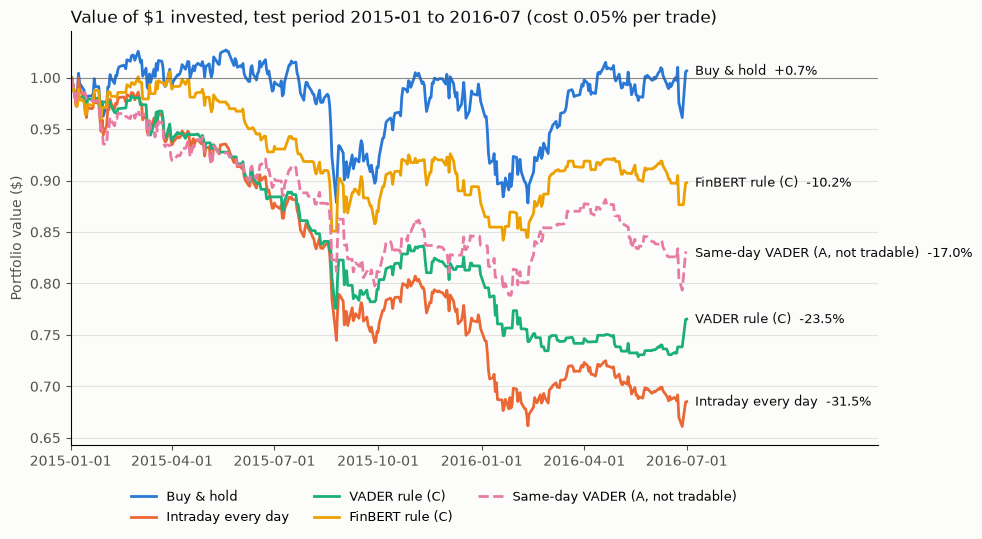

In [41]:
import matplotlib.pyplot as plt

# 颜色：数据可视化规范里已验证的默认分类配色，按固定顺序取前 5 个
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]
fig, ax = plt.subplots(figsize=(10, 5.5), facecolor="#fcfcfb")
ax.set_facecolor("#fcfcfb")
for (name, sig, r, intra), color in zip(strategies, COLORS):
    w = wealth_curve(run_strategy(sig, r, COST, intra))
    style = "--" if "not tradable" in name else "-"
    ax.plot(dates, w, color=color, lw=2, ls=style, label=name)
    ax.annotate(f"{name}  {w[-1] - 1:+.1%}", (dates.iloc[-1], w[-1]), xytext=(6, 0),
                textcoords="offset points", va="center", fontsize=9, color="#0b0b0b")
ax.axhline(1, color="#52514e", lw=0.8, alpha=0.6)
ax.set_title("Value of $1 invested, test period 2015-01 to 2016-07 (cost 0.05% per trade)",
             loc="left", fontsize=12, color="#0b0b0b")
ax.set_ylabel("Portfolio value ($)", color="#52514e")
ax.grid(axis="y", color="#52514e", alpha=0.15)
for side in ["top", "right"]:
    ax.spines[side].set_visible(False)
ax.tick_params(colors="#52514e")
ax.legend(loc="upper center", bbox_to_anchor=(0.45, -0.08), ncol=3, frameon=False, fontsize=9)
ax.set_xlim(dates.iloc[0], dates.iloc[-1] + pd.Timedelta(days=170))   # 右边留出位置写直接标签
ax.set_xticks(pd.date_range("2015-01-01", "2016-07-01", freq="3MS"))      # 刻度只画到数据结束
plt.tight_layout()
plt.show()

### 6.2 交易成本有多重要？

In [42]:
rows62 = []
for cost in [0.0, 0.0002, 0.0005]:
    for name, sig, r, intra in strategies:
        s = summary(run_strategy(sig, r, cost, intra), name)
        rows62.append({"cost": f"{cost:.2%}", "strategy": name, "total_return": s["total_return"], "sharpe": s["sharpe"]})
pd.DataFrame(rows62).pivot(index="strategy", columns="cost", values=["total_return", "sharpe"]).round(3)

total_return               sharpe         \
cost                                    0.00%  0.02%  0.05%  0.00%  0.02%   
strategy                                                                    
Buy & hold                              0.007  0.007  0.007  0.108  0.107   
FinBERT rule (C)                        0.132  0.032 -0.102  0.752  0.235   
Intraday every day                      0.000 -0.140 -0.315  0.074 -0.604   
Same-day VADER (A, not tradable)       -0.100 -0.129 -0.170 -0.495 -0.666   
VADER rule (C)                         -0.065 -0.137 -0.235 -0.339 -0.810   

                                         
cost                              0.05%  
strategy                                 
Buy & hold                        0.105  
FinBERT rule (C)                 -0.539  
Intraday every day               -1.621  
Same-day VADER (A, not tradable) -0.922  
VADER rule (C)                   -1.511

### 6.3 和 2000 个抛硬币策略比
对每条新闻规则，生成 2000 个随机策略：每天以**和这条规则相同的比例**随机决定持有（开盘买、收盘卖）还是空仓。这样持有天数和交易成本都一样，唯一的区别是"挑哪些天持有"——如果新闻真的有用，新闻规则挑的日子应该比随机挑的好。分别在成本 0 和 0.05% 下比较。

In [43]:
rng = np.random.default_rng(SEED)
rows63 = []
for name, sig, r, intra in strategies[2:4]:
    rand_sig = (rng.random(size=(2000, len(dates))) < sig.mean()).astype(int)
    for cost in [0.0, COST]:
        s = summary(run_strategy(sig, r, cost, intra), name)
        rand = pd.DataFrame([summary(run_strategy(x, r, cost, intra), "random") for x in rand_sig])
        rows63.append({"strategy": name, "cost": f"{cost:.2%}", "total_return": s["total_return"],
                       "random median": rand["total_return"].median(),
                       "random 95% range": f"{rand.total_return.quantile(0.025):+.1%} ~ {rand.total_return.quantile(0.975):+.1%}",
                       "beats % of random (return)": (rand["total_return"] < s["total_return"]).mean(),
                       "beats % of random (sharpe)": (rand["sharpe"] < s["sharpe"]).mean()})
pd.DataFrame(rows63).set_index(["strategy", "cost"]).round(3)

total_return  random median random 95% range  \
strategy         cost                                                  
VADER rule (C)   0.00%        -0.065         -0.005  -15.9% ~ +19.2%   
                 0.05%        -0.235         -0.184   -31.3% ~ -2.1%   
FinBERT rule (C) 0.00%         0.132          0.002  -16.5% ~ +18.6%   
                 0.05%        -0.102         -0.206   -34.1% ~ -5.8%   

                        beats % of random (return)  beats % of random (sharpe)  
strategy         cost                                                           
VADER rule (C)   0.00%                       0.235                       0.244  
                 0.05%                       0.236                       0.282  
FinBERT rule (C) 0.00%                       0.928                       0.922  
                 0.05%                       0.926                       0.930

### Stage 6 summary
- **Plain buy & hold was the hardest strategy to beat**: over the test period (Jan 2015 – Jul 2016) the Dow went roughly sideways, and $1 became **$1.007 (+0.7%)**, with a maximum drawdown of −14.5%.
- **Trading every day is expensive**: buying at every open and selling at every close earned about **0%** even with zero costs (in this period the gains came overnight, not during the day), and **−31.5%** once a 0.05% cost per trade is charged — 756 trades in 378 days add up.
- **The tradable news rules lose money after costs**: with yesterday's news deciding whether to hold the Dow from open to close, the VADER rule returns **−23.5%** and the FinBERT rule **−10.2%** (cost 0.05% per trade). Both are worse than buy & hold, both in return and in risk-adjusted terms (Sharpe −1.51 and −0.54 versus +0.11).
- **Costs decide everything**: with zero costs the FinBERT rule would have made **+13.2%** (Sharpe 0.75), better than buy & hold. At 0.02% it falls to +3.2%, and at 0.05% to −10.2%. The VADER rule loses money at every cost level.
- **Is the FinBERT result skill or luck? Most likely luck.** Against 2,000 random strategies that hold on the same share of days, the FinBERT rule beats 93% (one-sided p ≈ 0.07). Two rules were tried, so the corrected p ≈ 0.14, which is not significant. Three more warning signs: the VADER rule beats only 24% of random strategies (the "news signal" does not even agree with itself); the FinBERT model *lost* to "always up" in training cross-validation (Stage 4); and Stage 5 showed that 378 days cannot separate a small edge from noise.
- **Even "cheating" does not pay here**: the same-day VADER rule, which needs news you cannot have at the time of trading, still loses 17.0% (−10.0% with zero costs). The same-day link found in Stage 5 is too weak to turn into money.
- **Conclusion for the retail investor**: in this test, trading on world-news sentiment made less money than doing nothing, mainly because of trading costs, and the one result that looks good is consistent with luck. **This is a prototype and not financial advice.**